In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from scipy.sparse import hstack  # Để concat sparse và dense nếu cần

In [2]:
!pip install gensim --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 94.3 MB/s eta 0:00:00


In [3]:
# load data from drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import pandas as pd

# Thay bằng link CSV thật của anh (phải là link công khai, trực tiếp đến file CSV)
url = '/content/drive/MyDrive/Bert/Data/clean_hochinhminh_khanhhoa_lamdong_binhdinh.csv' # Ví dụ: 'https://raw.githubusercontent.com/cs109/2014_data/master/countries.csv'

# Đọc file CSV từ URL
df = pd.read_csv(url)

# In ra 5 dòng đầu tiên
print(df.head(5))

   stt                hotel_name    country province_raw review_name  score  \
0    1    TTR Skypool View Hotel  Việt Nam       Đà Lạt        (k17   10.0   
1    2           Prime New Hotel  Việt Nam    Nha Trang         (mr    8.0   
2    3  The MCR Luxury Nha Trang  Việt Nam    Nha Trang        ,như   10.0   
3    4  Lavender Nha Trang Hotel  Việt Nam    Nha Trang        -dhn   10.0   
4    5      NAMI HOTEL Nha Trang  Việt Nam    Nha Trang        . pi    7.0   

   hotel_avg_score  deviation stay_duration  \
0              7.7        2.3         1 đêm   
1              7.8        0.2         3 đêm   
2              6.9        3.1         1 đêm   
3              8.9        1.1         1 đêm   
4              7.3       -0.3         6 đêm   

                                room_type  ...  \
0               Phòng Deluxe Giường Đôi  ...   
1    Suite Có Giường Cỡ King Nhìn Ra Biển  ...   
2    Phòng Deluxe Giường Đôi/2 Giường Đơn  ...   
3  Phòng Superior Giường Đôi Với Cửa Sổ 

In [5]:
df['review_info'] = df[['room_type_id', 'stay_duration_id', 'group_type_id']].values.tolist()
useful_columns = [
    'final',          # text chính để embed
    'hotel_info',
    'review_info',
    'score',
   # string list 7 số (sẽ convert sau)
    # thêm các cột khác bạn thấy quan trọng
]
df = df[useful_columns]
print(df.head(5))

                                               final  \
0  đánh giá: xuất_sắc ưu điểm: tốt về chất_lượng ...   
1  đánh giá: tiếc là đi vào ngày trời âm_u biển đ...   
2  đánh giá: xuất_sắc ưu điểm: phòng_ốc sạch_sẽ t...   
3  đánh giá: xuất_sắc ưu điểm: phòng sạch_sẽ gần ...   
4  đánh giá: hài_lòng ưu điểm: đối_diện biển rất ...   

                            hotel_info   review_info  score  
0  [8.4, 7.9, 7.9, 8.0, 8.0, 8.5, 8.2]   [408, 1, 3]   10.0  
1  [8.5, 7.7, 8.0, 8.0, 8.3, 8.9, 8.5]  [1205, 3, 0]    8.0  
2  [7.8, 6.6, 7.1, 5.5, 7.3, 6.7, 6.9]   [638, 1, 0]   10.0  
3  [9.2, 8.9, 9.1, 9.2, 9.3, 9.1, 9.2]   [985, 1, 0]   10.0  
4  [8.0, 7.6, 7.5, 7.7, 8.1, 8.7, 9.2]   [512, 6, 0]    7.0  


In [6]:
df.loc[:, 'label'] = df['score'].astype(int)
hotel_features = pd.json_normalize(df['hotel_info']).add_prefix('h_').fillna('')
review_features = pd.json_normalize(df['review_info']).add_prefix('r_').fillna('')

# Nếu chỉ dùng text → bỏ qua ghép, trực tiếp:
X_text = df['final']

# Nếu muốn ghép metadata vào text (thường cho kết quả tốt hơn):
df['final_enhanced'] = (
    df['hotel_info'].apply(lambda x: f"Hotel {x.get('name', 'Unknown')} - {x.get('stars', '')} stars | " if isinstance(x, dict) else "")
    + df['final']
)

X = df['final']

y = df['label']


In [7]:
from sklearn.model_selection import train_test_split

# Giả sử docs = df['final'] và labels = df['label']
docs = df['final']
labels = df['score'].astype(int)

# Bước 1: Tách tập Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    docs, labels, test_size=0.2, random_state=42
)

# Bước 2: Tách tập Validation từ tập Train hiện tại (15% của 80% còn lại)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=42
)

# Kiểm tra quân số các tập
print(f"--- KẾT QUẢ CHIA DỮ LIỆU ---")
print(f"Tổng mẫu: {len(docs)}")
print(f"Tập Train (68%): {len(X_train)} mẫu")
print(f"Tập Validation (12%): {len(X_val)} mẫu")
print(f"Tập Test (20%): {len(X_test)} mẫu")

--- KẾT QUẢ CHIA DỮ LIỆU ---
Tổng mẫu: 41136
Tập Train (68%): 27971 mẫu
Tập Validation (12%): 4937 mẫu
Tập Test (20%): 8228 mẫu


In [8]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from gensim.models import Word2Vec
import nltk
from nltk.tokenize import word_tokenize
nltk.download('punkt')  # chỉ cần chạy 1 lần

class MeanEmbeddingVectorizer(BaseEstimator, TransformerMixin):
    def __init__(self, word2vec_model, vector_size=100):
        self.word2vec = word2vec_model
        self.vector_size = vector_size

    def fit(self, X, y=None):
        return self  # không cần fit gì thêm

    def transform(self, X):
        def get_mean_vector(text):
            tokens = word_tokenize(text.lower())
            vectors = [self.word2vec.wv[word] for word in tokens
                       if word in self.word2vec.wv]
            if len(vectors) == 0:
                return np.zeros(self.vector_size)
            return np.mean(vectors, axis=0)

        return np.array([get_mean_vector(doc) for doc in X])

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


In [9]:
import nltk

# Download cả hai để chắc chắn
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
# from gensim.models import Word2Vec           # giả sử bạn đã import rồi
# from your_custom_vectorizer import MeanEmbeddingVectorizer  # vectorizer của bạn

# ────────────────────────────────────────────────
# 1. Train Word2Vec (giữ nguyên như cũ)
# ────────────────────────────────────────────────
sentences = [word_tokenize(text.lower()) for text in X_train]  # hoặc toàn bộ dữ liệu

w2v_model = Word2Vec(
    sentences=sentences,
    vector_size=150,
    window=5,
    min_count=2,
    workers=4,
    sg=1,                  # skip-gram thường tốt hơn cho review ngắn
    epochs=20
)

# ────────────────────────────────────────────────
# 2. Tạo pipeline với DecisionTreeClassifier
# ────────────────────────────────────────────────
model_pipeline = Pipeline([
    ('word2vec', MeanEmbeddingVectorizer(w2v_model, vector_size=150)),
    ('dt', DecisionTreeClassifier(
        # Các tham số quan trọng - bạn có thể điều chỉnh
        criterion='gini',               # hoặc 'entropy' / 'log_loss'
        max_depth=12,                   # rất quan trọng! Không giới hạn → dễ overfit
        min_samples_split=8,            # tối thiểu samples để split node
        min_samples_leaf=4,             # tối thiểu samples ở lá
        max_features='sqrt',            # giống RF, thử 'log2' hoặc None
        class_weight='balanced',        # xử lý imbalance (rất hay cho review)
        random_state=42,
        # ccp_alpha=0.001,              # nếu muốn pruning (post-pruning)
    ))
])

In [11]:
# 3. Train và predict như bình thường
model_pipeline.fit(X_train, y_train)
y_pred = model_pipeline.predict(X_test)

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import torch
import textwrap   # để in đẹp hơn nếu cần

# ----------------------------------------------------------------------
# Đảm bảo y_test và y_pred ở dạng numpy array (phổ biến nhất)
# ----------------------------------------------------------------------
if isinstance(y_test, torch.Tensor):
    y_test_np    = y_test.cpu().numpy()
else:
    y_test_np    = np.asarray(y_test)

if isinstance(y_pred, torch.Tensor):
    y_pred_np    = y_pred.cpu().numpy()
else:
    y_pred_np    = np.asarray(y_pred)

# Nếu là multi-class và y_pred là probability → lấy argmax
if len(y_pred_np.shape) > 1 and y_pred_np.shape[1] > 1:
    y_pred_np = np.argmax(y_pred_np, axis=1)

# ----------------------------------------------------------------------
# Tính các metric cơ bản
# ----------------------------------------------------------------------
accuracy = accuracy_score(y_test_np, y_pred_np)

# In header
print("\n" + "="*80)
print("              MODEL EVALUATION ON TEST SET")
print("="*80)

# Accuracy chi tiết
print(f"\nOverall Accuracy:")
print(f"  • {accuracy:.4f}  ({accuracy*100:.2f}%)")
print("-"*60)

# Classification Report (chi tiết, 4 chữ số thập phân)
print("\nClassification Report:")
print(classification_report(
    y_test_np,
    y_pred_np,
    digits=4,
    zero_division=0,
    target_names=[str(c) for c in model_pipeline.classes_]   # nếu có class names đẹp
    # target_names = ['Negative', 'Positive']  # → bạn có thể hard-code tên lớp nếu muốn
))

# ----------------------------------------------------------------------
# Confusion Matrix - cả dạng số lượng và dạng chuẩn hóa (%)
# ----------------------------------------------------------------------
cm = confusion_matrix(y_test_np, y_pred_np)

print("\nConfusion Matrix (Raw counts):")
print(cm)

# Chuẩn hóa theo hàng (precision-oriented: tỷ lệ dự đoán đúng trong mỗi lớp thật)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
cm_normalized = np.nan_to_num(cm_normalized)  # tránh NaN nếu có lớp không có mẫu

# ----------------------------------------------------------------------
# Một số metric tổng hợp bổ sung (macro / weighted)
# ----------------------------------------------------------------------
print("\nSummary Metrics:")
print(f"  Macro    Avg Precision : {precision_score(y_test_np, y_pred_np, average='macro', zero_division=0):.4f}")
print(f"  Macro    Avg Recall    : {recall_score(y_test_np, y_pred_np, average='macro', zero_division=0):.4f}")
print(f"  Macro    Avg F1-score  : {f1_score(y_test_np, y_pred_np, average='macro', zero_division=0):.4f}")
print(f"  Weighted Avg F1-score : {f1_score(y_test_np, y_pred_np, average='weighted', zero_division=0):.4f}")

# Kết thúc đẹp
# ----------------------------------------------------------------------
torch.cuda.empty_cache() if torch.cuda.is_available() else None

print("\n" + "="*80)
print(f"HOÀN TẤT ĐÁNH GIÁ!  •  Accuracy = {accuracy*100:.2f}%")
print("="*80 + "\n")


              MODEL EVALUATION ON TEST SET

Overall Accuracy:
  • 0.4259  (42.59%)
------------------------------------------------------------

Classification Report:
              precision    recall  f1-score   support

           5     0.1622    0.3454    0.2208       194
           6     0.0857    0.1840    0.1169       212
           7     0.1426    0.3085    0.1950       483
           8     0.2341    0.3514    0.2810      1107
           9     0.2984    0.2681    0.2825      1712
          10     0.7708    0.5312    0.6289      4520

    accuracy                         0.4259      8228
   macro avg     0.2823    0.3314    0.2875      8228
weighted avg     0.5314    0.4259    0.4617      8228


Confusion Matrix (Raw counts):
[[  67   36   46   25   10   10]
 [  44   39   66   36   18    9]
 [  57   70  149  129   39   39]
 [  82   96  240  389  139  161]
 [  74   89  222  373  459  495]
 [  89  125  322  710  873 2401]]

Summary Metrics:
  Macro    Avg Precision : 0.2823
  Mac

In [13]:
import pickle
import os

save_dir= '/content/drive/MyDrive/Bert/Model/W2vec-DT/'
os.makedirs(save_dir, exist_ok=True)
file_path = os.path.join(save_dir, 'hotel_review_classifier_word2vec_DT.pkl')
try:
    with open(file_path, 'wb') as f:
        pickle.dump(model_pipeline, f, protocol=pickle.HIGHEST_PROTOCOL)

    # Kiểm tra file có tồn tại và có kích thước > 0 không
    if os.path.exists(file_path) and os.path.getsize(file_path) > 0:
        print(f"✅ LƯU THÀNH CÔNG!")
        print(f"→ File đã được lưu tại: {os.path.abspath(file_path)}")
        print(f"→ Kích thước file: {os.path.getsize(file_path) / (1024 * 1024):.2f} MB")
    else:
        print("⚠️ Lưu file nhưng file không hợp lệ (kích thước = 0 hoặc không tồn tại).")

except Exception as e:
    print("❌ LỖI KHI LƯU MÔ HÌNH:")
    print(f"→ Chi tiết lỗi: {type(e).__name__}: {str(e)}")
    print("→ Gợi ý: Kiểm tra xem model_pipeline đã fit chưa, hoặc thử downgrade dill về 0.3.8 như trước.")




✅ LƯU THÀNH CÔNG!
→ File đã được lưu tại: /content/drive/MyDrive/Bert/Model/W2vec-DT/hotel_review_classifier_word2vec_DT.pkl
→ Kích thước file: 7.71 MB


In [14]:
import pickle
import os

def load_model(save_dir='/content/drive/MyDrive/Bert/Model/W2vec-DT/',
               filename='hotel_review_classifier_word2vec_DT.pkl'):

    file_path = os.path.join(save_dir, filename)

    if not os.path.exists(file_path):
        print(f"❌ Không tìm thấy file: {file_path}")
        return None

    if os.path.getsize(file_path) == 0:
        print(f"❌ File tồn tại nhưng rỗng: {file_path}")
        return None

    try:
        with open(file_path, 'rb') as f:
            model_pipeline = pickle.load(f)

        print("✅ LOAD THÀNH CÔNG!")
        print(f"→ Đường dẫn: {os.path.abspath(file_path)}")
        print(f"→ Kích thước file: {os.path.getsize(file_path) / (1024 * 1024):.2f} MB")

        # Optional: kiểm tra xem model có predict được không
        try:
            test_text = ["khách sạn rất tốt", "dịch vụ tệ quá"]
            preds = model_pipeline.predict(test_text)
            print("→ Test predict nhanh:", preds)
        except Exception as e:
            print("⚠️ Model load được nhưng predict thử bị lỗi:", str(e))

        return model_pipeline

    except Exception as e:
        print("❌ LỖI KHI LOAD MODEL:")
        print(f"→ {type(e).__name__}: {str(e)}")
        print("\nGợi ý khắc phục:")
        print("1. Kiểm tra phiên bản pickle / python / thư viện có khớp lúc save không")
        print("2. Nếu lỗi liên quan đến gensim → có thể cần cài đúng phiên bản gensim lúc save")
        print("3. Thử dùng joblib thay pickle nếu trước đó dùng joblib để lưu")
        return None

In [15]:
model = load_model()

if model is not None:
    # dự đoán
    text = "khách sạn sạch sẽ, nhân viên thân thiện"
    prediction = model.predict([text])[0]
    probability = model.predict_proba([text])[0] if hasattr(model, 'predict_proba') else None

    print(f"Văn bản: {text}")
    print(f"Dự đoán: {prediction}")
    if probability is not None:
        print(f"Xác suất: {probability}")

✅ LOAD THÀNH CÔNG!
→ Đường dẫn: /content/drive/MyDrive/Bert/Model/W2vec-DT/hotel_review_classifier_word2vec_DT.pkl
→ Kích thước file: 7.71 MB
→ Test predict nhanh: [5 7]
Văn bản: khách sạn sạch sẽ, nhân viên thân thiện
Dự đoán: 6
Xác suất: [0.         0.96314438 0.         0.03685562 0.         0.        ]


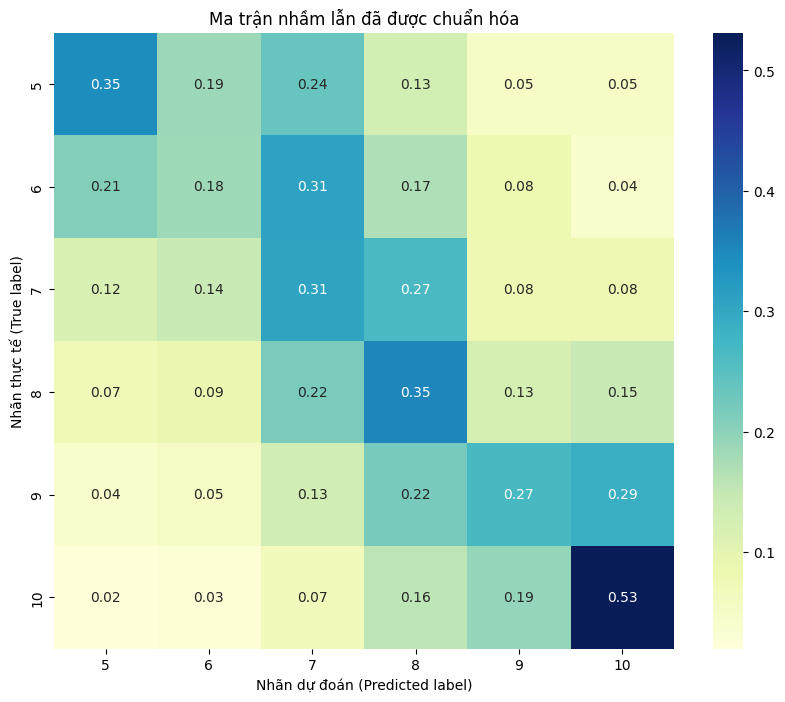

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns   # chỉ cần nếu bạn muốn dùng seaborn ở phần sau


y_pred = model_pipeline.predict(X_test)

cm = confusion_matrix(y_test, y_pred, labels=model_pipeline.classes_)

cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Lấy tên các lớp dựa trên điểm rating thực tế
class_names = [str(i) for i in range(5, 11)]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='YlGnBu',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Ma trận nhầm lẫn đã được chuẩn hóa')
plt.ylabel('Nhãn thực tế (True label)')
plt.xlabel('Nhãn dự đoán (Predicted label)')
plt.show()


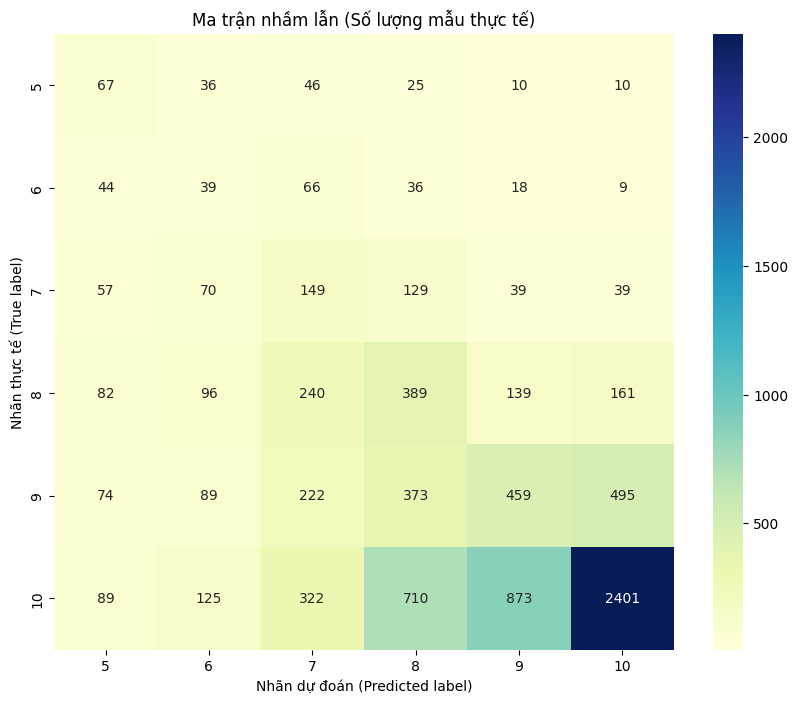

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Tính ma trận nhầm lẫn (đây là dạng số lượng gốc)
cm = confusion_matrix(y_test, y_pred, labels=model_pipeline.classes_)
# 2. Tên các lớp (từ 5 đến 10)
class_names = [str(i) for i in range(5, 11)]

plt.figure(figsize=(10, 8))

# 3. Vẽ Heatmap với biến 'cm' gốc
sns.heatmap(
    cm,
    annot=True,      # Hiển thị số lên ô
    fmt='d',         # ĐỊNH DẠNG LÀ SỐ NGUYÊN (d = decimal/integer)
    cmap='YlGnBu',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('Ma trận nhầm lẫn (Số lượng mẫu thực tế)')
plt.ylabel('Nhãn thực tế (True label)')
plt.xlabel('Nhãn dự đoán (Predicted label)')
plt.show()